# Exploratory Data Analysis

### Objective:

The initial objective of this project is to build a regression model to predict final mathematics performance (**G3**) using information available at earlier stages of the course.

This section explores the dataset to understand variable types, distributions, missing values, and potential relationships. Insights gained here will guide feature preprocessing and later modelling decisions.

#### Imports and Settings

In [1]:
import os
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import (
    chi2_contingency,
    spearmanr,
    pointbiserialr,
    f_oneway
)
from statsmodels.stats.contingency_tables import Table


pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")

#### Loading The Dataset

In [2]:
path = os.path.join("..", "data", "raw", "Math-Students.csv")

df = pd.read_csv(path)

#### Initial Inspection

In [3]:
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10


#### Data Summary

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 399 entries, 0 to 398
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      399 non-null    object
 1   sex         399 non-null    object
 2   age         399 non-null    int64 
 3   address     399 non-null    object
 4   famsize     399 non-null    object
 5   Pstatus     399 non-null    object
 6   Medu        399 non-null    int64 
 7   Fedu        399 non-null    int64 
 8   Mjob        399 non-null    object
 9   Fjob        399 non-null    object
 10  reason      399 non-null    object
 11  guardian    399 non-null    object
 12  traveltime  399 non-null    int64 
 13  studytime   399 non-null    int64 
 14  failures    399 non-null    int64 
 15  schoolsup   399 non-null    object
 16  famsup      399 non-null    object
 17  paid        399 non-null    object
 18  activities  399 non-null    object
 19  nursery     399 non-null    object
 20  higher    

#### Summary Statistics

Summary statistics for numeric features are examined to understand central tendency, spread, and potential anomalies.

In [5]:
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,399.000000,399.000000,399.000000,399.000000,399.000000,399.000000,399.000000,399.000000,399.000000,399.000000,399.000000,399.000000,399.000000,399.000000,399.000000,399.000000
mean,16.709273,2.761905,2.536341,1.443609,2.035088,0.330827,3.954887,3.233083,3.097744,1.476190,2.288221,3.558897,5.651629,10.879699,10.676692,10.380952
std,1.278225,1.096340,1.092716,0.695429,0.835020,0.740655,0.898335,0.994107,1.113178,0.887552,1.281737,1.384013,7.983113,3.315195,3.760845,4.571073
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,8.500000,8.000000
50%,17.000000,3.000000,3.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.500000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,13.500000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


Inspection of the descriptive statistics highlights **absences** as a potentially irregular feature. While the mean number of absences is relatively low (≈ 5.7), the maximum value reaches 75 with a standard deviation of ≈ 8.0, indicating a highly right-skewed distribution with extreme values. This motivates closer examination of absences in subsequent distributional and outlier analyses.

#### Missing Values

In [6]:
df.isna().sum().sort_values(ascending=False)

school        0
paid          0
G2            0
G1            0
absences      0
health        0
Walc          0
Dalc          0
goout         0
freetime      0
famrel        0
romantic      0
internet      0
higher        0
nursery       0
activities    0
famsup        0
sex           0
schoolsup     0
failures      0
studytime     0
traveltime    0
guardian      0
reason        0
Fjob          0
Mjob          0
Fedu          0
Medu          0
Pstatus       0
famsize       0
address       0
age           0
G3            0
dtype: int64

No missing values were detected.

#### Variable types

Columns are classified into three main types for further analysis:

- **Binary features**: columns with exactly two unique values.
- **Numeric features**: continuous or ordinal numeric columns, excluding binaries.
- **Categorical features**: object-type columns, excluding binaries.

This categorization facilitates tailored visualizations and statistical analyses in later sections.

In [7]:
binary_cols = [col for col in df.columns if df[col].nunique() == 2]
num_cols = [col for col in df.select_dtypes(include='number').columns if col not in binary_cols]
cat_cols = [col for col in df.select_dtypes(include='object').columns if col not in binary_cols]

feature_table = pd.DataFrame({
    "Binary features": pd.Series(binary_cols),
    "Numeric features": pd.Series(num_cols),
    "Categorical features": pd.Series(cat_cols)
})

feature_table

,Binary features,Numeric features,Categorical features
0,school,age,Mjob
1,sex,Medu,Fjob
2,address,Fedu,reason
3,famsize,traveltime,guardian
4,Pstatus,studytime,NaN
5,schoolsup,failures,NaN
6,famsup,famrel,NaN
7,paid,freetime,NaN
8,activities,goout,NaN
9,nursery,Dalc,NaN


#### Inspecting Unique Values

In [8]:
for col in binary_cols:
    print(f"{col}: {df[col].unique()}")

school: ['GP' 'MS']
sex: ['F' 'M']
address: ['U' 'R']
famsize: ['GT3' 'LE3']
Pstatus: ['A' 'T']
schoolsup: ['yes' 'no']
famsup: ['no' 'yes']
paid: ['no' 'yes']
activities: ['no' 'yes']
nursery: ['yes' 'no']
higher: ['yes' 'no']
internet: ['no' 'yes']
romantic: ['no' 'yes']


In [9]:
for col in cat_cols:
    print(f"{col}: {df[col].unique()}")

Mjob: ['at_home' 'health' 'other' 'services' 'teacher']
Fjob: ['teacher' 'other' 'services' 'health' 'at_home']
reason: ['course' 'other' 'home' 'reputation']
guardian: ['mother' 'father' 'other']


## Initial Exploration of Grades (G1, G2, G3)

In [10]:
grades = ["G1", "G2", "G3"]
df[grades].describe()

,G1,G2,G3
count,399.000000,399.000000,399.000000
mean,10.879699,10.676692,10.380952
std,3.315195,3.760845,4.571073
min,3.000000,0.000000,0.000000
25%,8.000000,8.500000,8.000000
50%,11.000000,11.000000,11.000000
75%,13.000000,13.000000,13.500000
max,19.000000,19.000000,20.000000


Examining the desciptive statistics for the three grade components — **G1** (first period), **G2** (second period), **G3** (final grade) — shows a slight **decrease** in mean grade from G1 → G2 → G3, whilst the standard deviation **increases**. This is contrary to the typical expectation that average performance improves and variability remains stable over time.

Distributions of **G1**, **G2**, **G3** were plotted for further investigation.

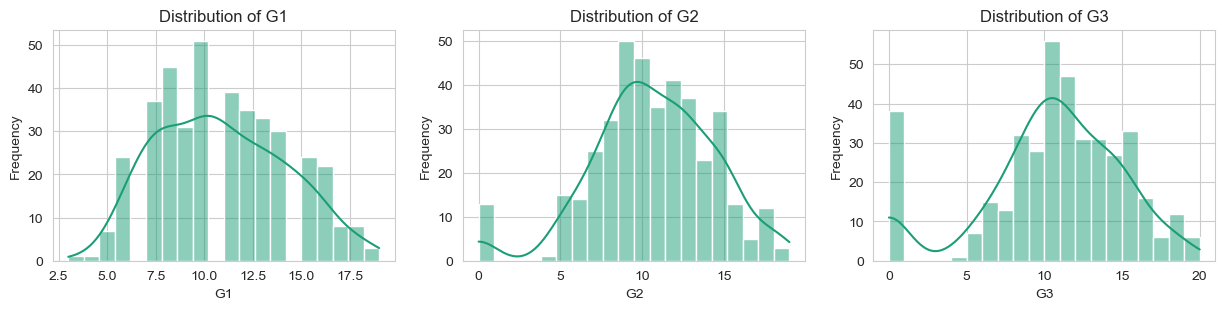

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3))

for i, G in enumerate(grades):
    sns.histplot(df[G], color="#1b9e77", kde=True, bins=20, ax=axes[i])
    axes[i].set_title(f"Distribution of {G}")
    axes[i].set_xlabel(G)
    axes[i].set_ylabel("Frequency")

plt.show()

The plots reveal notable **spikes at zero** in **G2** and **G3**, which likely correspond to missing performance data due to **course non-completion** or **non-attendance**, rather than genuine academic performance. These zeros help to explain the unexpected mean and standard deviation trends.

### Grade Statistics for G3 > 0

In [12]:
df[df["G3"] != 0][["G1", "G2", "G3"]].describe()

,G1,G2,G3
count,361.000000,361.000000,361.000000
mean,11.232687,11.310249,11.473684
std,3.240565,3.162828,3.244654
min,3.000000,5.000000,4.000000
25%,9.000000,9.000000,9.000000
50%,11.000000,11.000000,11.000000
75%,14.000000,13.000000,14.000000
max,19.000000,19.000000,20.000000


After excluding students with **G3 = 0**:

- The mean grade now **increases** slightly from G1 → G2 → G3, as expected.
- The standard deviation now remains stable.
- This confirms that the zeros in G2 and G3 are driving the anomalies observed in the full dataset.

### Relationship Between G2 and G3 Zeros

In [13]:
df[df["G2"] == 0][["G1", "G2", "G3"]].describe()

,G1,G2,G3
count,13.000000,13.0,13.0
mean,7.461538,0.0,0.0
std,2.436370,0.0,0.0
min,4.000000,0.0,0.0
25%,6.000000,0.0,0.0
50%,7.000000,0.0,0.0
75%,9.000000,0.0,0.0
max,12.000000,0.0,0.0


Examining students with **G2 = 0** shows:

- Every student with **G2 = 0 also has G3 = 0**.
- Missing grades appear to **cascade forwards**, supporting the interpretation that these zeros indicate **course withdrawal / non-completion** rather than isolated non-attendance or poor performance.

### Summary Statistics for G3 = 0 Cases

In [14]:
df[df["G3"] == 0].describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.0,38.000000,38.000000,38.0
mean,17.078947,2.315789,2.289474,1.605263,1.973684,0.921053,3.842105,3.131579,3.210526,1.342105,1.921053,3.605263,0.0,7.526316,4.657895,0.0
std,1.302421,1.016227,1.112773,0.789782,0.914946,1.075063,1.000711,0.875216,1.318433,0.534047,1.171314,1.284828,0.0,1.811925,3.700083,0.0
min,15.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.0,4.000000,0.000000,0.0
25%,16.000000,2.000000,1.000000,1.000000,1.000000,0.000000,3.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.0,6.000000,0.000000,0.0
50%,17.000000,2.000000,2.000000,1.000000,2.000000,1.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,0.0,7.000000,5.000000,0.0
75%,18.000000,3.000000,3.000000,2.000000,2.000000,1.750000,4.750000,4.000000,4.000000,2.000000,2.000000,5.000000,0.0,9.000000,8.000000,0.0
max,19.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,3.000000,5.000000,5.000000,0.0,12.000000,10.000000,0.0


Summary statistics for students with **G3 = 0** reveal that **all** of these students have **zero recorded absences**. This statistically unlikely pattern suggests an **artefact of administrative recording**, where attendance information may not have been recorded for students who did not complete the course, further supporting the interpretation that **G3 = 0 corresponds to non-completion rather than true academic performance**.

# Analysis of Course Non-Completion

### The Non-Completion Problem

Initial inspection of the target variable (**G3**) reveals a significant cluster of zero-value observations. Evidence suggest these cases represent **course non-completion** rather than a genuine academic score. As such, **G3 captures two distinct phenomena** within a single variable:

- **Academic Achievement:** The continuous range of scores ($0 < G3 \leq 20$) reflecting a student’s final exam performance.
- **Course Completion:** A binary state ($G3 = 0$ vs. $G3 > 0$) indicating whether a student completed the course (i.e. sat the final exam).

Attempting to model both of these outcomes with a single regression model would likely bias results and reduce predictive accuracy for the majority of students.

### Strategic Motivation

To define an appropriate modelling strategy, it is first necessary to determine whether non-completion is a random occurrence or a predictable outcome. This distinction directly informs the structure of the analysis:

- **Random Occurrence:** If no meaningful patterns are found, non-completion cases can be treated as noise and excluded to improve the robustness of the performance model.
- **Predictable Outcome:** If systematic patterns exist, a **two-stage modelling approach** is justified:
  - **Risk Model:** A classification model to estimate the probability of non-completion.
  - **Performance Model:** A regression model to predict **G3**, conditional on course completion.

The following analysis examines the extent to which G3 = 0 cases can be explained by observed features, in order to assess the feasibility of modelling non-completion risk.

### G1 Performance and Course Completion

To examine whether early academic performance is associated with course non-completion, the distributions of first-period grades (G1) are compared between completers (G3 > 0) and non-completers (G3 = 0). Kernel density estimates are used to visualise and contrast the overall shape, spread, and central tendency of grades across the two groups, revealing whether systematic differences emerge at an early stage.

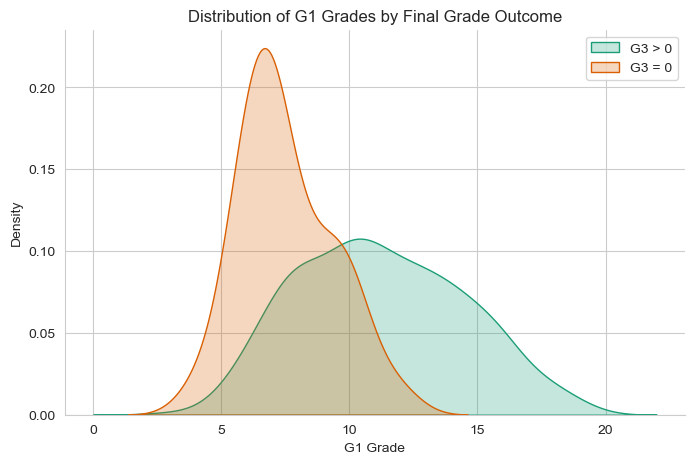

In [15]:
palette = sns.color_palette("Dark2")

plt.figure(figsize=(8,5))

sns.kdeplot(
    data=df[df["G3"] > 0],
    x="G1",
    fill=True,
    color=palette[0],
    label="G3 > 0"
)

sns.kdeplot(
    data=df[df["G3"] == 0],
    x="G1",
    fill=True,
    color=palette[1],
    label="G3 = 0"
)

plt.xlabel("G1 Grade")
plt.ylabel("Density")
plt.title("Distribution of G1 Grades by Final Grade Outcome")
plt.legend()
sns.despine()
plt.show()

The distribution of first-period grades (G1) clearly differs between completers and non-completers. Non-completers (G3 = 0) tend to have substantially lower early grades, with their distribution concentrated around the lower end of the scale, whilst completers (G3 > 0) exhibit a broader distribution shifted towards higher grades.

The clear separation in central tendency suggests that early academic performance is strongly associated with eventual course completion, with low-scoring students at higher risk of withdrawing from the course. However, the substantial overlap between the two distributions, combined with the significant class imbalance, limits the predictive usefulness of G1 in isolation: although associated with increased risk of non-completion, the majority of low-scoring students still complete the course.

This indicates that G1 alone is not a reliable indicator of non-completion, but may contribute valuable signal when considered alongside additional features.

In [16]:
(df[df["G1"] <= 6]["G3"] == 0).mean()

0.36363636363636365

Among students with low early performance (**G1 ≤ 6**), the non-completion rate rises to ∼36%, compared to a much lower baseline rate of ∼9.5% across the full dataset.

Despite this higher rate, the majority of these students still complete the course.

### Binary / Categorical Features and Course Non-Completion

Chi-square tests of independence are used to evaluate the relationship between categorical and binary features and course non-completion (**G3 = 0**). Alongside statistical significance (p-values), Cramér’s V is reported to quantify the strength of association, enabling meaningful comparison across features. This provides a structured basis for identifying which variables are most strongly linked to course non-completion.

In [17]:
df["withdrawn"] = (df["G3"] == 0)

chi2_results = []
chi2_cols = binary_cols + cat_cols

for col in chi2_cols:
    
    contingency_table = pd.crosstab(df[col], df["withdrawn"])
    
    chi2, p, dof, ex = chi2_contingency(contingency_table)
    
    n = contingency_table.values.sum()
    min_dim = min(contingency_table.shape) - 1
    
    cramers_v = np.sqrt(chi2 / (n * min_dim)) if min_dim > 0 else 0
    
    chi2_results.append({
        "Feature": col,
        "p-value": p,
        "Significant": p < 0.05,
        "Effect Size (Cramér's V)": round(cramers_v, 3)
    })

chi2_ranked_df = (
    pd.DataFrame(chi2_results)
    .sort_values("p-value")
    .reset_index(drop=True)
)

print("Binary/Categorical Feature Significance (Chi-Square)")
display(chi2_ranked_df)

Binary/Categorical Feature Significance (Chi-Square)


,Feature,p-value,Significant,Effect Size (Cramér's V)
0,paid,0.002759,True,0.150
1,higher,0.004954,True,0.141
2,romantic,0.012026,True,0.126
3,schoolsup,0.086385,False,0.086
4,reason,0.108791,False,0.123
5,famsize,0.205017,False,0.063
6,sex,0.358340,False,0.046
7,Pstatus,0.430105,False,0.039
8,Mjob,0.470093,False,0.094
9,guardian,0.471328,False,0.061


The chi-square analysis identifies three binary features—**paid**, **higher**, and **romantic**—as statistically significant predictors of course non-completion. However, effect sizes remain modest, indicating that these relationships, while present, are not strong in isolation. Most other features show little to no meaningful association with non-completion.

To examine the practical significance of these findings, non-completion rates are compared across groups for the significant features. This provides a clearer view of how each variable influences non-completion risk relative to the overall baseline.

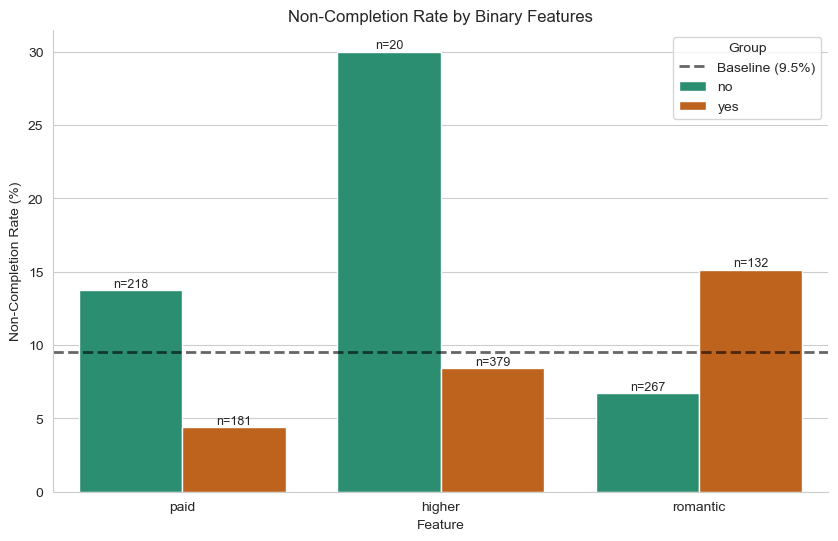

In [18]:
binary_non_completion_features = ["paid", "higher", "romantic"]

baseline = (df["G3"] == 0).mean() * 100

plot_df = (
    df.melt(
        id_vars="G3",
        value_vars=binary_non_completion_features,
        var_name="Feature",
        value_name="Group"
    )
    .groupby(["Feature", "Group"])
    .agg(
        **{
            "Sample Size (N)": ("G3", "size"),
            "Non-Completion Rate (%)": ("G3", lambda x: (x == 0).mean() * 100)
        }
    )
    .reset_index()
)

feature_order = binary_non_completion_features
group_order = sorted(plot_df["Group"].unique())

plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=plot_df,
    x="Feature",
    y="Non-Completion Rate (%)",
    hue="Group",
    order=feature_order,
    hue_order=group_order,
    palette="Dark2"
)

plt.axhline(
    baseline,
    color="black",
    linestyle="--",
    linewidth=2,
    alpha=0.6,
    label=f"Baseline ({baseline:.1f}%)"
)

for container, group in zip(ax.containers, group_order):
    subset = (
        plot_df[plot_df["Group"] == group]
        .set_index("Feature")
        .reindex(feature_order)
    )
    labels = [f"n={int(n)}" for n in subset["Sample Size (N)"]]
    ax.bar_label(container, labels=labels, padding=0, fontsize=9)

plt.title("Non-Completion Rate by Binary Features")
plt.ylabel("Non-Completion Rate (%)")
plt.legend(title="Group")
sns.despine()
plt.show()

The bar chart illustrates clear differences in non-completion rates across the significant binary features, providing practical context to the statistical results. For **higher**, students who do not intend to pursue higher education show a substantially higher non-completion rate (approximately 30%) compared to those who do (around 8%). However, this group represents a relatively small portion of the sample (n = 20), so this estimate should be interpreted with some caution.

A similar, though less pronounced, pattern is observed for **romantic**, where students in a romantic relationship have a higher non-completion rate (~ 15%) than those who are not (~ 7%). In contrast, students receiving **paid support** (paid = yes) exhibit a lower non-completion rate (~ 4%) compared to those who do not (~ 14%), suggesting a potential protective effect.

Whilst these differences are substantial relative to the baseline (~ 9.5%), no single feature fully explains non-completion. Instead, these variables provide partial signals, reinforcing that non-completion is influenced by multiple interacting factors.

### Ordinal Features and Course Non-Completion

Cochran–Armitage trend tests are used to assess whether ordinal features exhibit systematic relationships with course non-completion (G3 = 0). Alongside statistical significance (p-values), Spearman’s rank correlation (ρ) is reported to quantify the strength and direction of these trends, enabling meaningful comparison across features. This provides a structured basis for identifying which ordinal variables show consistent increases or decreases in non-completion risk.

In [19]:
ordinal_results = []

ordinal_cols = ["age", "Medu", "Fedu", "traveltime", "studytime", "failures", "famrel", 
                "freetime", "goout", "Dalc", "Walc", "health"]

for col in ordinal_cols:
    
    cont_table = pd.crosstab(df[col], df["withdrawn"])
    stat_table = Table(cont_table)
    res = stat_table.test_ordinal_association()
    
    corr, _ = spearmanr(df[col], df["withdrawn"])
    
    ordinal_results.append({
        "Ordinal Feature": col,
        "Trend p-value": res.pvalue,
        "Significant": res.pvalue < 0.05,
        "Effect Size (Spearman ρ)": round(corr, 3)
    })

ordinal_trends_ranked_df = (
    pd.DataFrame(ordinal_results)
    .sort_values("Trend p-value")
    .reset_index(drop=True)
)

print("Ordinal Feature Trend Significance (Cochran-Armitage)")
display(ordinal_trends_ranked_df)

Ordinal Feature Trend Significance (Cochran-Armitage)


,Ordinal Feature,Trend p-value,Significant,Effect Size (Spearman ρ)
0,failures,2.411072e-07,True,0.262
1,Medu,5.029251e-03,True,-0.137
2,age,1.071117e-02,True,0.100
3,Walc,6.338515e-02,False,-0.095
4,Fedu,1.033475e-01,False,-0.075
5,traveltime,1.319480e-01,False,0.075
6,famrel,4.158578e-01,False,-0.033
7,freetime,5.081515e-01,False,-0.035
8,goout,5.114394e-01,False,0.032
9,studytime,6.336728e-01,False,-0.033


The trend analysis highlights **failures** as the most influential ordinal feature, with a statistically significant positive relationship and the largest observed effect size (ρ ≈ 0.26). This indicates that as the number of past academic failures increases, the likelihood of course non-completion rises. Smaller but significant effects are also observed for **Medu** and **age**, although their magnitudes are notably weaker.

Most other ordinal features show little evidence of a meaningful trend, with near-zero effect sizes and non-significant p-values, suggesting limited predictive value in isolation.

To further examine the practical impact of past academic failure, the relationship between the number of prior failures and non-completion rate is visualised directly. This provides a clearer view of how risk evolves across levels of academic difficulty and allows comparison with the overall baseline rate.

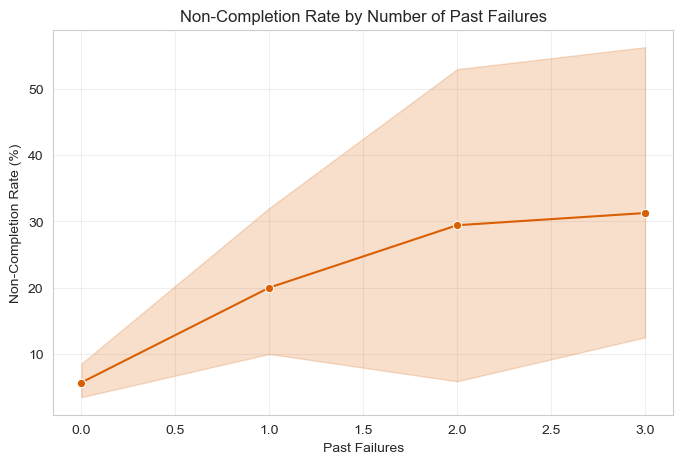

In [20]:
plt.figure(figsize=(8, 5))

sns.lineplot(data=df, x="failures", y="withdrawn", marker="o", color=palette[1])

plt.title("Non-Completion Rate by Number of Past Failures")
plt.ylabel("Non-Completion Rate (%)") 
plt.xlabel("Past Failures")
plt.grid(alpha=0.3)

plt.gca().yaxis.set_major_formatter(lambda x, _: f"{x*100:.0f}")

plt.show()

Non-completion rates increase with the number of past academic failures, rising from around 5% for students with no prior failures to over 30% for those with three. The largest increase occurs between zero and one failure.

This pattern highlights past academic failure as a strong indicator of elevated non-completion risk, consistent with the earlier trend analysis. The wider uncertainty at higher failure counts reflects smaller sample sizes; however, the overall upward trend remains pronounced.

These findings suggest that past academic failure is one of the most informative individual indicators of non-completion risk. However, even at higher levels of failure, the majority of students still go on to complete the course. As such, it represents an important component within a broader set of interacting risk factors, rather than a decisive predictor on its own.

### Summary and Modelling Decision

The analysis indicates that course non-completion is **not random**, but exhibits clear and consistent relationships with multiple features. Early academic performance (G1) shows a strong association with non-completion, whilst prior academic failures emerges as the most informative individual predictor, with risk increasing substantially as the number of prior failures rises. Several binary features (higher, paid, romantic) also contribute additional signal, although their effects are comparatively modest.

Whilst no single feature is a decisive predictor in isolation, their combined effect provides a clear and systematic signal distinguishing non-completers from the broader cohort.

These findings demonstrate that non-completion is a predictable outcome, supporting the use of a **probabilistic modelling approach** rather than treating these cases as noise and removing them from the dataset.


### Modelling Strategy

Consequently, a **two-stage modelling framework** is adopted:

- **Non-Completion Risk Model:** A classification model is used to estimate the probability that a student does not complete the course.
- **Performance Model:** A regression model is then applied to predict final grade (G3) for students who complete the course.

This approach separates the fundamentally different processes captured within G3, allowing each to be modelled more accurately while preserving the underlying structure of the data.

# Analysis of Final Performance (Conditional on Course Completion)

With the modeling strategy for non-completion established, the remainder of the exploratory analysis focuses on the subset of students who completed the course ($G3>0$). By removing the $G3=0$ cases, the analysis can isolate the features that drive academic achievement without the statistical bias introduced by non-completion.

In [21]:
df_completers = df[df["withdrawn"] == 0].copy()

## Numerical and Ordinal Feature Analysis

### Peliminary Feature Distributions

To understand the composition of the completing cohort (**G3 > 0**), distributions are visualised for several key numerical and ordinal features.

### Academic Performance

After removing non-completers, the distributions of **G1**, **G2**, and **G3** are re-examined:

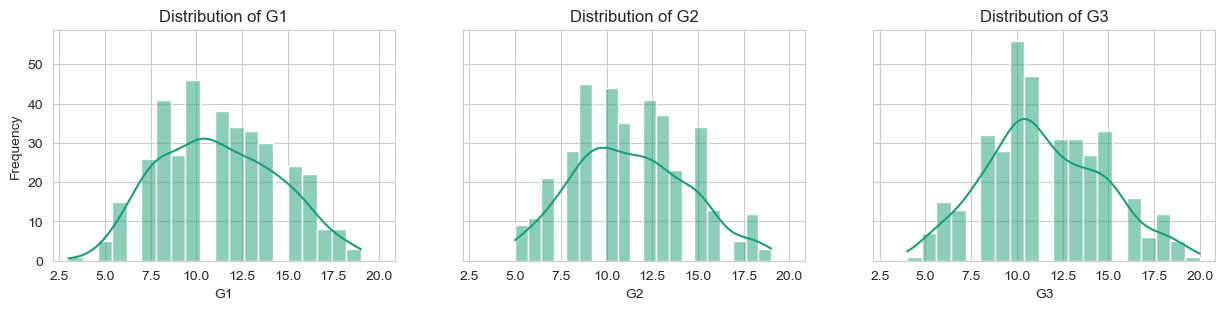

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3), sharex=True, sharey=True)

for i, G in enumerate(grades):
    sns.histplot(df_completers[G], color=palette[0], kde=True, bins=20, ax=axes[i])
    axes[i].set_title(f"Distribution of {G}")
    axes[i].set_xlabel(G)
    axes[i].set_ylabel("Frequency")

plt.show()

All three grade variables now exhibit near-normal distributions, centred around the mid-range (approximately 10–12). The slight shift towards higher values in later assessments suggests modest improvement over time for some students.

### Age and Prior Academic Failures

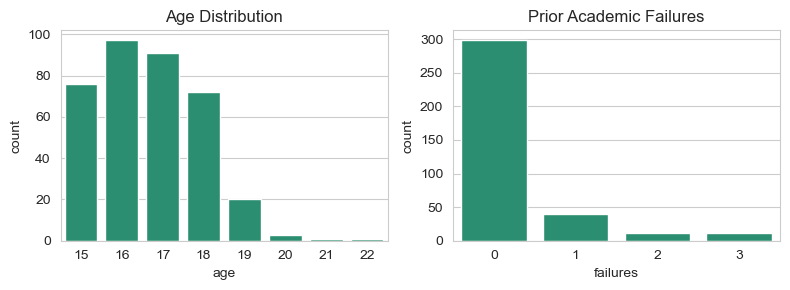

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3)) 

sns.countplot(data=df_completers, x="age", color=palette[0], ax=axes[0])
axes[0].set_title("Age Distribution")

sns.countplot(data=df_completers, x="failures", color=palette[0], ax=axes[1])
axes[1].set_title("Prior Academic Failures")

plt.tight_layout()
plt.show()

The cohort is primarily composed of students aged 15-18, and the vast majority of completers have zero prior academic failures.

### Student Engagement and Lifestyle

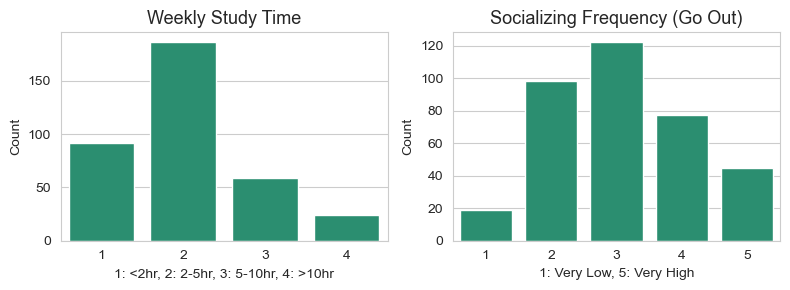

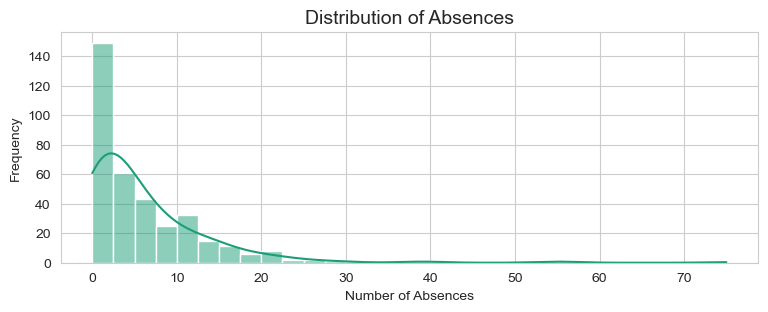

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3))

sns.countplot(data=df_completers, x="studytime", color=palette[0], ax=axes[0])
axes[0].set_title("Weekly Study Time", fontsize=13)
axes[0].set_xlabel("1: <2hr, 2: 2-5hr, 3: 5-10hr, 4: >10hr")
axes[0].set_ylabel("Count")

sns.countplot(data=df_completers, x="goout", color=palette[0], ax=axes[1])
axes[1].set_title("Socializing Frequency (Go Out)", fontsize=13)
axes[1].set_xlabel("1: Very Low, 5: Very High")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 3))

sns.histplot(df_completers["absences"], kde=True, color=palette[0], bins=30)
plt.title("Distribution of Absences", fontsize=14)
plt.xlabel("Number of Absences")
plt.ylabel("Frequency")
plt.show()

Whilst **studytime** and **goout** exhibit relatively balanced distributions, **absences** is heavily right-skewed, with a small number of extreme values well beyond the interquartile range. While these observations may reflect genuine behaviour, they represent statistical outliers and may disproportionately influence modelling, motivating further analysis. The use of a log transformation, as well as approaches to handling these extreme values, is explored later in this section.

### Spearman Rank Correlations


Several variables in this dataset are ordinal in nature but encoded numerically. Accordingly, relationships between numerical and ordinal features are explored non-parametrically using **Spearman rank correlation**. 

Spearman rank correlation is a non-parametric measure that assesses:
- The strength and direction of a **monotonic association** between two ordinal or continuous variables based on their ranked values.


A Spearman correlation matrix is plotted for all numerical and ordinal features:

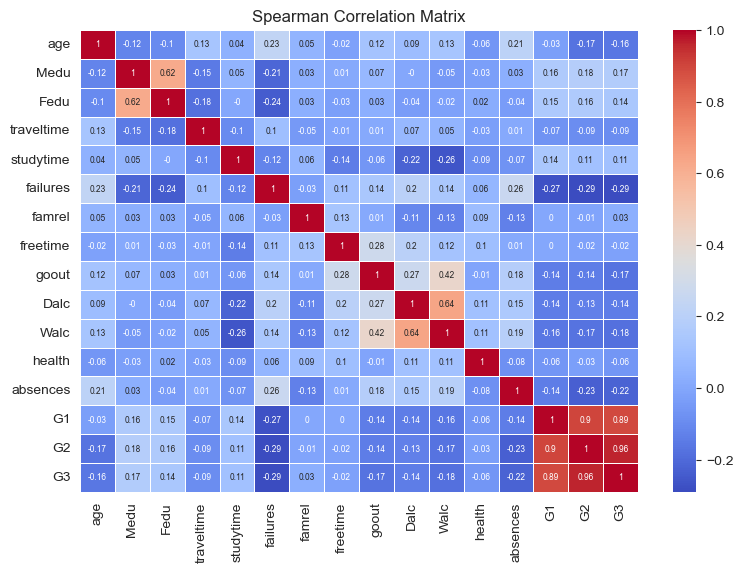

In [25]:
corr = df_completers[num_cols].corr(method="spearman").round(2)

plt.figure(figsize=(9, 6))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    linewidths=0.5,
    annot_kws={"size": 6}  
)
plt.title("Spearman Correlation Matrix")
plt.show()

Spearman correlations with G3 are also ranked by magnitude:

In [26]:
G3_corr = corr["G3"].drop("G3")

G3_corr_sorted = G3_corr.reindex(G3_corr.abs().sort_values(ascending=False).index)

print(f"Correlations with G3 (2dp):\n{G3_corr_sorted}")


Correlations with G3 (2dp):
G2            0.96
G1            0.89
failures     -0.29
absences     -0.22
Walc         -0.18
Medu          0.17
goout        -0.17
age          -0.16
Fedu          0.14
Dalc         -0.14
studytime     0.11
traveltime   -0.09
health       -0.06
famrel        0.03
freetime     -0.02
Name: G3, dtype: float64


### Notable Relationships

Several strong relationships are identified from the Spearman correlation matrix:

- **Dalc and Walc** exhibit a strong positive correlation ($r = 0.64$), suggesting that both variables capture a common pattern of alcohol     consumption behaviour. These features may be combined into a single alcohol-use measure to reduce redundancy.


- **Medu and Fedu** also show a strong positive correlation ($r = 0.62$), reflecting shared household socio-economic and educational           backgrounds. A combined parental education feature may provide a more concise representation of household educational           environment.


- **Failures** exhibits a moderate negative correlation with final grade ($r = -0.29$), indicating that prior academic difficulty is             associated with lower final performance. This feature likely captures cumulative academic challenges and may interact with       other engagement-related variables such as absences or study time.


- **absences** similarly exhibits a moderate negative correlation with final grade ($r = -0.22$), suggesting that greater numbers of absences are associated with lower academic performance. This likely reflects reduced engagement with the course and fewer opportunities for learning and assessment.


- **G1 and G2** are strongly correlated with G3 ($r = 0.89$ and $r = 0.96$, respectively), suggesting that prior grades are highly predictive of final outcomes.         Including these variables in predictive models may introduce leakage or dominate other predictors; therefore, models should be   evaluated both with and without prior grades.

### Prior Academic Failures

As the strongest non-grade predictor of final performance ($r = -0.29$), **Failures** demonstrates a definitive, downwards staircase effect on student outcomes.

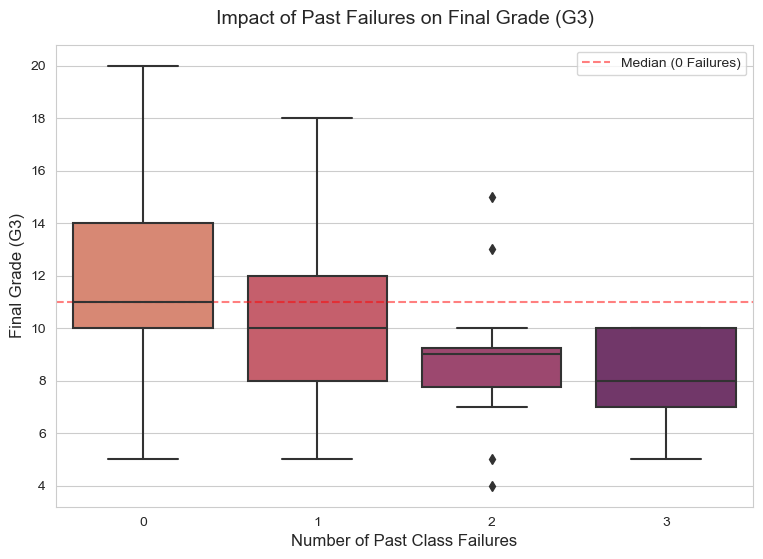

In [27]:
plt.figure(figsize=(9, 6))

sns.boxplot(x="failures", y="G3", data=df_completers, palette="flare")

plt.title("Impact of Past Failures on Final Grade (G3)", fontsize=14, pad=15)
plt.xlabel("Number of Past Class Failures", fontsize=12)
plt.ylabel("Final Grade (G3)", fontsize=12)

median_zero = df[df["failures"] == 0]["G3"].median()
plt.axhline(median_zero, color="red", linestyle="--", alpha=0.5, label="Median (0 Failures)")

plt.legend()
plt.show()

Every additional failure exhibits a systematic downward shift of the entire G3 distribution, with just one failure resulting in a significant decrease in median G3. Students with 2 or 3 failures see their performance ceiling collapse, as even their highest-achieving individuals rarely reach the median of the zero-failure baseline.

Although the sample sizes for these higher tiers are small, the consistent downward shift in the interquartile ranges (IQR) indicates a clear negative relationship.

Overall, failures emerges as one of the most informative features in the dataset, demonstrating strong predictive value for both final grade and course non-completion. It effectively captures cumulative academic difficulty, linking poorer performance with substantially increased risk of non-completion.

### Addressing High-Absence Outliers

Whilst most students maintain high attendance, the raw absences data is heavily right skewed, with a small subset of students possessing extremely high recorded absence levels. Although these students are statistical outliers, they may still provide meaninful information if handled correctly.

A boxplot of the **raw absences** data is examined to assess the overall spread of the variable and to visualise statistical outliers.

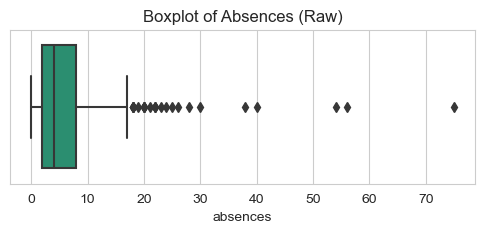

In [28]:
plt.figure(figsize=(6, 2))
sns.boxplot(x=df_completers["absences"], palette="Dark2")
plt.title("Boxplot of Absences (Raw)")
plt.show()

To formally identify extreme values, statistical outliers are defined using the interquartile range (IQR) criterion. Observations exceeding 1.5 × IQR above the third quartile are flagged as high-absence cases.

In [29]:
Q1 = df_completers["absences"].quantile(0.25)
Q3 = df_completers["absences"].quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR
outliers = df_completers[df_completers["absences"] > upper_bound]

print(f"N.o. statistical outliers: {len(outliers)}")
print(f"Largest value: {outliers['absences'].max()}")

N.o. statistical outliers: 25
Largest value: 75


A small number of observations fall beyond this threshold, with the maximum absence count substantially exceeding the upper bound.

To assess whether these extreme absence values are associated with academic outcomes, a binary indicator for high absences is created and compared against final grade (G3).

The indicator is defined as follows:

- **high_absences = True**: absences > upper bound  
- **high_absences = False**: absences ≤ upper bound  

where the upper bound is defined using the interquartile range (IQR) criterion:

- $\text{Upper Bound} = Q_3 + 1.5 \times \text{IQR}$

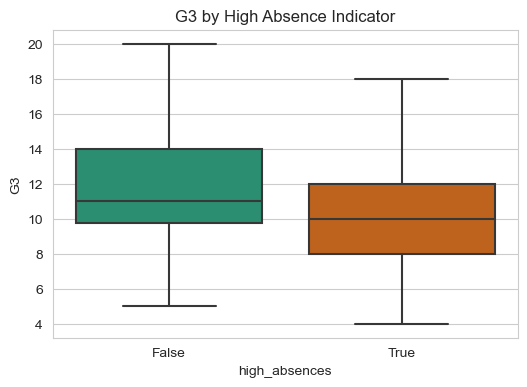

In [30]:
df_completers["high_absences"] = df_completers["absences"] > upper_bound

plt.figure(figsize=(6, 4))
sns.boxplot(x="high_absences", y="G3", data=df_completers, palette="Dark2")
plt.title("G3 by High Absence Indicator")
plt.show()

The G3 distribution for the high-absence gorup shows a clear downward shift across all quartiles. This suggests that high absenteeism is associated with poorer overall performance, likely due to significantly reduced exposure to instructional learning and assessments rather than random variation. This pattern reinforces that high absenteeism is a meaningful predictor of academic performance and that removing these extreme cases could result in the loss of valuable information.

However, the magnitude of extreme absence values (up to ~75) presents a challenge for modelling. Such values could disproportionately influence distance-based and linear models, potentially biasing results. If these observations are retained, their influence must be handled carefully.

A log-transformation ($\ln(x+1)$) is explored to reduce the influence of these extreme values without compromising their underlying signal.

Raw Absences skew: 3.6139882092344546
Log-transformed skew:  -0.06331976987680275


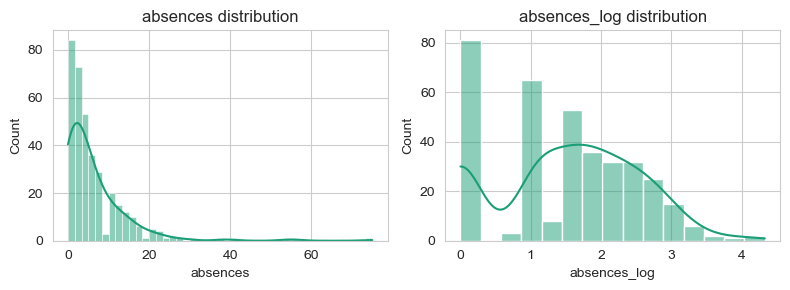

In [31]:
df_completers["absences_log"] = np.log1p(df_completers["absences"])

fig, axes = plt.subplots(1, 2, figsize=(8, 3))

sns.histplot(df_completers["absences"], color="#1b9e77", kde=True, ax=axes[0])
axes[0].set_title("absences distribution")

sns.histplot(df_completers["absences_log"], color="#1b9e77", kde=True, ax=axes[1])
axes[1].set_title("absences_log distribution")
plt.tight_layout()
plt.show

print("Raw Absences skew:", df_completers["absences"].skew())
print("Log-transformed skew: ", df_completers["absences_log"].skew())

The transformation successfully reduces skew from ~ 3.6 for the raw data to ~ -0.6 for the transformed data. Whilst the transformation appears bimodal due to the high frequency of perfect attendance (0 absences), it successfully 'decompresses' the lower values and pulls in the extreme outliers to a manageable range that ensures the model captures the relationship without being dominated by a handful of extreme cases.

### Summary of Numerical / Ordinal Feature Analysis

Overall, the numerical/ordinal feature analysis suggests that prior grades, academic history, and engagement are the strongest predictors of G3, with **G2**, **G1**, **failures** and **absences** showing the strongest relationships. Several features exhibit strong inter-correlation (**Dalc/Walc** and **Medu/Fedu**), motivating consideration of combined measures or careful handling of multicollinearity. Distributional inspection highlighted **absences** as highly skewed with rare but meaningful extreme values. These values are retained and a log transform is applied to reduce skewness and limit the influence of extreme observations whilst preserving their underlying signal.

## Binary Feature Analysis

Several features in the dataset are binary (e.g. *yes/no* indicators).  
These variables are analysed to assess whether the presence or absence of a given characteristic is associated with differences in final academic performance (G3).

Binary features are:
- Treated as **categorical variables for visualisation** (boxplots and stripplots)
- **Temporarily encoded as 0/1** solely for statistical analysis using point-biserial correlation

### Binary Feature Correlations with Final Grade (G3)

**Point-biserial correlation** is used to quantify the relationship between binary features and the continuous outcome variable (G3)

Point-biserial correlation is a special case of Pearson correlation that measures:
- The strength and direction of association between a **binary variable** and a **continuous variable**

Binary categories are encoded as 0 and 1 in a consistent order for each feature.
Encoding is applied locally for analysis only and not retained in the dataset.

In [32]:
def encode_binary(series):
    categories = sorted(series.dropna().unique())
    mapping = {categories[0]: 0, categories[1]: 1}
    return series.map(mapping), mapping

def ordered_percentages(series, mapping):
    percents = series.value_counts(normalize=True) * 100
    return {cat: round(percents.get(cat, 0), 1) for cat in mapping.keys()}

For each binary feature, the following are computed:
- Point-biserial correlation coefficient (r)
- Corresponding p-value
- Encoding mapping used for the analysis
- Class distribution (%) for interpretability and imbalance assessment

Features are ranked by **absolute correlation strength**.

In [33]:
binary_results = []

for col in binary_cols:
    encoded, mapping = encode_binary(df_completers[col])
    r, p = pointbiserialr(encoded, df_completers["G3"])
    
    binary_results.append({
        "Feature": col,
        "Correlation (r)": r,
        "p-value": p,
        "Mapping": mapping,
        "Class Distribution (%)": ordered_percentages(df_completers[col], mapping)
    })
    
binary_corr_df = (
    pd.DataFrame(binary_results)
      .sort_values("Correlation (r)", key=abs, ascending=False)
      .reset_index(drop=True)
)

binary_corr_df

,Feature,Correlation (r),p-value,Mapping,Class Distribution (%)
0,schoolsup,-0.229390,0.000011,"{'no': 0, 'yes': 1}","{'no': 86.1, 'yes': 13.9}"
1,internet,0.141373,0.007139,"{'no': 0, 'yes': 1}","{'no': 17.2, 'yes': 82.8}"
2,address,0.120372,0.022168,"{'R': 0, 'U': 1}","{'R': 21.6, 'U': 78.4}"
3,school,-0.119963,0.022629,"{'GP': 0, 'MS': 1}","{'GP': 87.3, 'MS': 12.7}"
4,higher,0.109068,0.038332,"{'no': 0, 'yes': 1}","{'no': 3.9, 'yes': 96.1}"
5,sex,0.084889,0.107354,"{'F': 0, 'M': 1}","{'F': 51.2, 'M': 48.8}"
6,activities,0.073074,0.165919,"{'no': 0, 'yes': 1}","{'no': 50.1, 'yes': 49.9}"
7,nursery,0.055898,0.289504,"{'no': 0, 'yes': 1}","{'no': 20.8, 'yes': 79.2}"
8,famsize,0.049265,0.350633,"{'GT3': 0, 'LE3': 1}","{'GT3': 70.4, 'LE3': 29.6}"
9,famsup,-0.046793,0.375368,"{'no': 0, 'yes': 1}","{'no': 39.3, 'yes': 60.7}"


Whilst several features reached statistical significance ($p < 0.05$), most exhibited weak overall effects.

- **School Support (schoolsup)**: The most significant binary predictor ($r = -0.23$). Interestingly, students receiving extra support tend to have lower final grades, likely indicating that this support is targeted towards students who are already struggling.

- **Access to Resources:** Both **internet** access and an **Urban** address correlate positively with performance, highlighting a slight "resource gap" in student outcomes.

- **Aspiration:** Whilst desire for higher education (**higher**) shows a positive correlation, the data is heavily imbalanced (**96% Yes**), making it a less reliable differentiator.


As the most significant binary feature, **schoolsup** is examined via a boxplot of **G3** across groups.

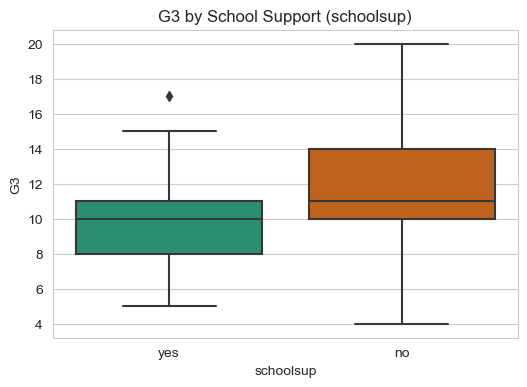

In [34]:
plt.figure(figsize=(6, 4))
sns.boxplot(x="schoolsup", y="G3", data=df_completers, palette="Dark2")
plt.title("G3 by School Support (schoolsup)")
plt.show()

Counterintuitively, students receiving additional school support (**yes**) exhibit lower median grades and a reduced upper range compared to their peers. This suggests that school support is a reactive intervention, targeted towards students already identified as struggling, rather than serving as a general performance booster.

### Summary of Binary Feature Analysis

Several binary features reached statistical significance ($p < 0.05$), however their overall correlations with G3 remained relatively weak. The most significant predictor was **School Support** ($r = -0.23$), where students receiving additional support showed lower median grades and reduced top scores. This indicates that school support is a reactive intervention targeted at struggling students. Additionally, **internet access** and **urban housing** showed a slight positive impact, suggesting that better access to resources provides a small but measurable performance advantage.

## Categorical Feature Analysis

Categorical features are explored to assess whether final grade (**G3**) differs across multi-class groups. As a first step, category frequencies are inspected to identify class imbalance and rare groups, which may affect interpretability and the reliability of group comparisons.

In [35]:
for col in cat_cols:
    counts = df_completers[col].value_counts()
    print(counts)

Mjob
other       127
services     94
teacher      58
at_home      50
health       32
Name: count, dtype: int64
Fjob
other       197
services    102
teacher      26
health       18
at_home      18
Name: count, dtype: int64
reason
course        128
reputation    101
home           97
other          35
Name: count, dtype: int64
guardian
mother    252
father     82
other      27
Name: count, dtype: int64


Category counts reveal some imbalance across features. For example, **guardian** is dominated by "mother", with relatively small "father" and "other" groups. These imbalances are important to keep in mind when interpreting group differences, as small groups can produce unstable estimates and visually noisy boxplots.

### Categorical Feature Associations with Final Grade (G3)

**One-way ANOVA** is used to assess whether multi-class categorical features are associated with differences in the continuous outcome variable (G3).

One-way ANOVA measures:

- Whether the mean value of a continuous variable differs significantly across two or more categories within a feature.

Features with larger F-statistics indicate greater separation between group means relative to within-group variation. ANOVA results are used as a guide for selecting categorical variables for further visual inspection using boxplots.


In [36]:
anova_results = []

for col in cat_cols:
    groups = [group["G3"].values for name, group in df_completers.groupby(col)]
    F, p = f_oneway(*groups)
    anova_results.append({"Feature": col, "F-score": F, "p-value": p})

anova_df = pd.DataFrame(anova_results).sort_values("F-score", ascending=False)
anova_df

,Feature,F-score,p-value
0,Mjob,4.012684,0.003384
1,Fjob,2.475717,0.044027
3,guardian,0.948229,0.388398
2,reason,0.436944,0.726698


- **Parental Occupation (Mjob and Fjob):** Both mother’s and father’s occupations are statistically significant predictors of student performance ($p < 0.05$), suggesting that household professional background is a key driver of academic success. This is likely linked to broader socioeconomic conditions and the home learning environment. Notably, the mother’s occupation ($F \approx 4.01$) shows a stronger relative impact on final grades than the father’s ($F \approx 2.48$).

- **Negligible Factors:** Features such as the student’s **guardian** and the **reason** for choosing the school show no statistical significance ($p > 0.38$). These variables do not appear to have a meaningful relationship with final grades and can therefore be deprioritised in modelling.


As the most significant categorical feature, **Mother's Job (Mjob)** is examined via a boxplot of G3 scores to visualise performance differences across groups. Categories are ordered by median grade to improve interpretability.

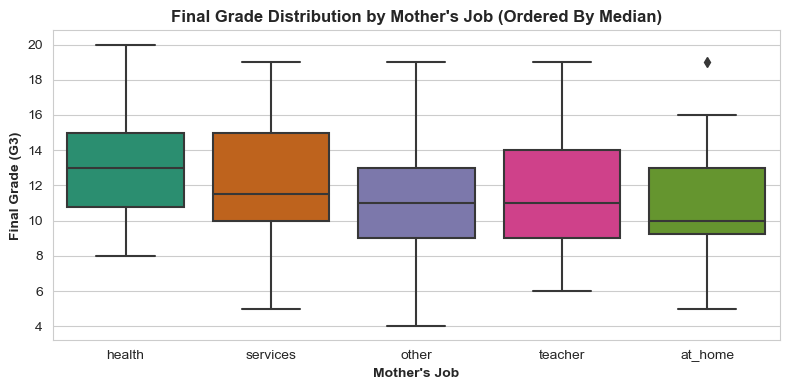

In [37]:
order = df_completers.groupby("Mjob")["G3"].median().sort_values(ascending=False).index

plt.figure(figsize=(8, 4))

sns.boxplot(
    data=df_completers,
    order=order,
    x="Mjob",
    y="G3",
    palette="Dark2"
)

plt.xlabel("Mother's Job", fontweight="bold")
plt.ylabel("Final Grade (G3)", fontweight="bold")
plt.title("Final Grade Distribution by Mother's Job (Ordered By Median)", fontweight="bold")

plt.tight_layout()
plt.show()

The boxplot shows a clear performance gradient across occupational categories, with students whose mothers work in **health** achieving the highest median grades, and a significantly higher performance floor. However, due to the small sample size ($n = 32$), this result should be interpreted cautiously. In contrast, the larger **services** and **other** categories exhibit wider spreads, demonstrating that as the sample size increases, there is more variety in student outcomes. Finally, the **at_home** group has the lowest median performance, although the presence of a high-performing outlier shows that individual excellence can still occur regardless of the overall group trend. 

In conclusion, mother’s occupation provides a useful baseline for expected performance, likely reflecting underlying socioeconomic conditions and the home learning environment. However, the high degree of individual variation suggests that personal and behavioural factors ultimately play a larger role in determining student outcomes.


### Summary of Categorical Feature Analysis

Testing via One-way ANOVA revealed that whilst student’s **guardian*** or **reason** for school choice have a negligible impact on final grades, parental occupation stands out as a significant predictor. Specifically, Mother’s Job (**Mjob**) demonstrated the strongest statistical relationship to G3 ($F \approx 4.01$). Visual analysis confirms a clear performance advantage for students whose mothers work in the health sector, however the high variance within groups indicates that professional background acts as a socioeconomic baseline rather than a deterministic constraint, with individual-level factors playing the primary role in driving student performance.

# EDA Summary

Initial exploration reveals that final grade (**G3**) captures two distinct aspects of the student outcome: **course completion** (whether a non-zero final grade is recorded) and **academic performance conditional on completion** (an integer value from 1-20).

Subsequent analysis demonstrates that non-completion is **not random**, but exhibits systematic relationships with multiple features. In particular, early performance (**G1**) and prior academic **failures** emerge as the most informative predictors, with failure history showing a strong and consistent increase in non-completion risk. Several binary features (**higher**, **paid**, **romantic**) contribute additional signal, however their effects are comparatively modest. **Absence data is missing for students who did not complete the course**, meaning **absences cannot be used as a predictor of non-completion** in this dataset. This limits the ability to directly assess the role of engagement in dropout risk.
Overall, non-completion appears to be driven by multiple interacting factors rather than any single variable.

These findings motivate a **two-stage modelling framework**, separating non-completion risk from academic performance in order to more accurately capture the underlying data-generating processes:

- **Non-Completion Risk Model:** A classification model to estimate the probability of non-completion.
- **Performance Model:** A regression model to predict **G3**, conditional on course completion.

When restricting to students who completed the course, analysis shows that **prior academic performance** remains the dominant driver of final grades, with **G2** and **G1** exhibiting the strongest relationships with G3. Measures of academic difficulty (**failures**) and engagement (**absences**) also play an important role. Several features exhibit high inter-correlation (e.g. **Dalc/Walc**, **Medu/Fedu**), indicating potential redundancy. Distributional analysis highlights **absences** as highly right-skewed with a small number of extreme but meaningful observations. These cases are retained and a log-transform is applied to limit their influence whilst preserving their underlying signal.

Binary and categorical features provide additional contextual insight but are generally weaker predictors of performance. In particular, **school support** appears to be a reactive intervention rather than a causal driver of improved outcomes, whilst **parental occupation** (especially **Mjob**) captures differences in baseline performance likely linked to socioeconomic factors. However, substantial within-group variation across all categories highlights that these factors are **not deterministic**, and that individual-level differences remain central to student success.

Overall, the analysis indicates that while structural and environmental factors influence outcomes, **academic history and engagement are the primary drivers of student outcomes**. These insights inform the subsequent modelling approach, ensuring that both predictive accuracy and interpretability are aligned with the underlying structure of the data.




